<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%206/MRayhanZamzami_JS06_Regresi_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS PRAKTIKUM - Multiple Linear Regression pada Medical Cost Personal Dataset

Dataset: insurance.csv (prediksi biaya medis personal).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset/insurance.csv')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


## Eksplorasi Data

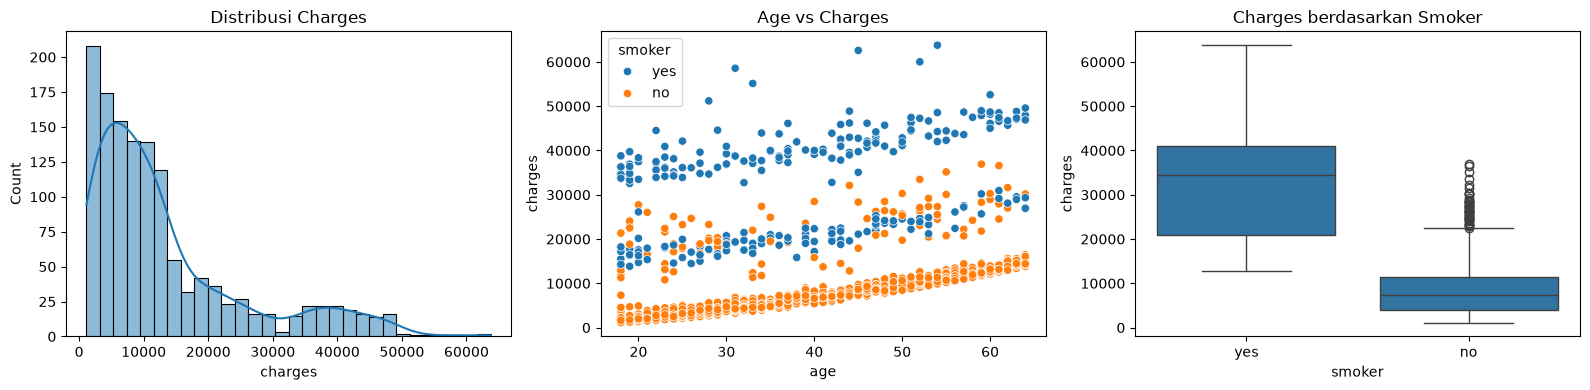

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['charges'], kde=True, ax=axes[0])
axes[0].set_title('Distribusi Charges')
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', ax=axes[1])
axes[1].set_title('Age vs Charges')
sns.boxplot(data=df, x='smoker', y='charges', ax=axes[2])
axes[2].set_title('Charges berdasarkan Smoker')
plt.tight_layout()
plt.show()

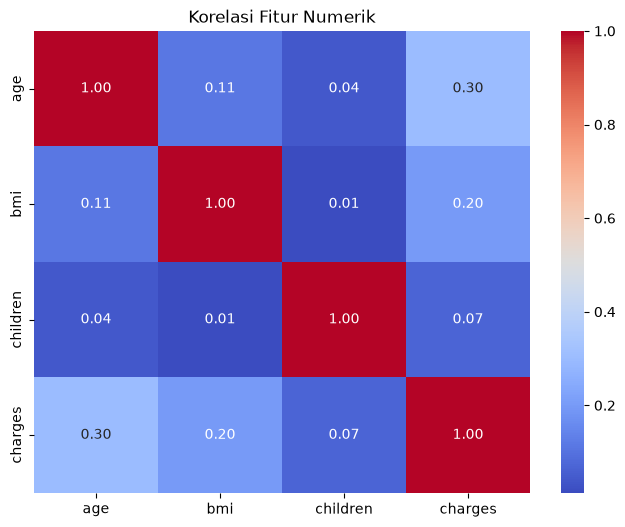

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Fitur Numerik')
plt.show()

## Preprocessing dan Pemodelan

In [5]:
# Encoding fitur kategorikal
df_model = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

X = df_model.drop('charges', axis=1)
y = df_model['charges']

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Shape X train:', X_train_scaled.shape)
print('Shape X test :', X_test_scaled.shape)

Shape X train: (1070, 8)
Shape X test : (268, 8)


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE      : {mae:,.2f}')
print(f'MSE      : {mse:,.2f}')
print(f'RMSE     : {rmse:,.2f}')
print(f'R-squared: {r2:.4f}')

MAE      : 4,181.19
MSE      : 33,596,915.85
RMSE     : 5,796.28
R-squared: 0.7836


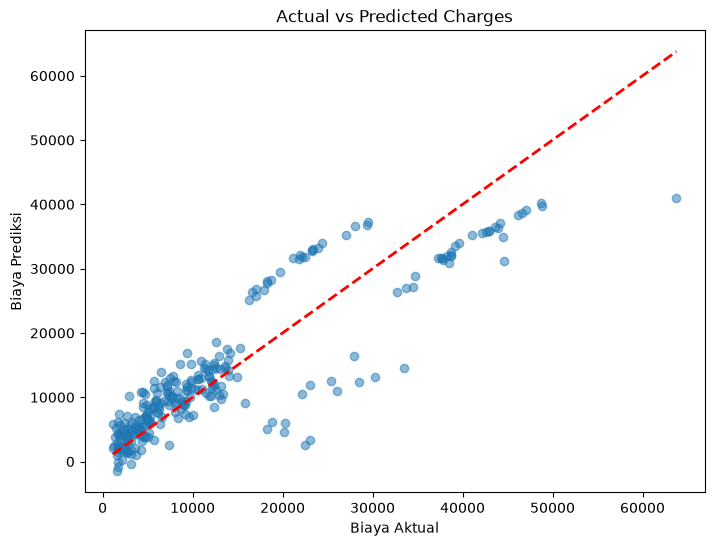

In [7]:
# Visualisasi aktual vs prediksi
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Biaya Aktual')
plt.ylabel('Biaya Prediksi')
plt.title('Actual vs Predicted Charges')
plt.show()

In [8]:
# Koefisien model
coef_df = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_
}).sort_values('Koefisien', key=abs, ascending=False)
coef_df

,Fitur,Koefisien
4,smoker_yes,9558.481409
0,age,3614.975415
1,bmi,2036.228123
2,children,516.890247
7,region_southwest,-349.110678
6,region_southeast,-290.157047
5,region_northwest,-158.140981
3,sex_male,-9.293101
